# Assignment 3: Unsupervised Learning, Dimensionality Reduction, and Anomaly Detection - NBA Draft Dataset (1989-2021)

This script performs a complete end-to-end Unsupervised Learning, Dimensionality Reduction, and Anomaly Detection on the `nbaplayersdraft.csv` dataset.

* **Student Name:** Amit Rizkan
* **ID:** 322430810
* **Institution:** Holon Institute of Technology (HIT)
* **Course:** Introduction to Data Science
* **Lecturer:** Dr. Uri Itai
* **TA:** Hanit Ohayon Hadad
* **Evaluator:** Dror Meirovich

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Set style
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Load Data & Preprocessing
df = pd.read_csv('nbaplayersdraft.csv')

# Numerical features for unsupervised learning
num_cols = [
    'overall_pick', 'years_active', 'games', 'minutes_played', 'points',
    'total_rebounds', 'assists', 'field_goal_percentage', '3_point_percentage',
    'free_throw_percentage', 'average_minutes_played', 'points_per_game',
    'average_total_rebounds', 'average_assists', 'win_shares',
    'win_shares_per_48_minutes', 'box_plus_minus', 'value_over_replacement'
]

# Impute missing values logically (0 games = 0 stats)
df_clean = df.copy()
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(0.0)

X = df_clean[num_cols].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data Matrix Shape: {X_scaled.shape}")

Data Matrix Shape: (1922, 18)


## Dataset Selection and Exploratory Context
This dataset contains historical NBA Draft records from 1989 to 2021. It was sourced from Basketball-Reference and tracks the career productivity of 1,922 drafted players across 24 columns, heavily populated with continuous numerical features (games, points, advanced metrics like VORP). 
* **Motivation:** The dataset is perfect for unsupervised learning because we lack a definitive "ground truth" for player archetypes or a pre-labeled anomaly flag. We want to discover if players naturally cluster by career trajectory rather than traditional positions, and identify extreme statistical anomalies.
* **Limitations/Biases:** The data suffers from Right-Censoring (active players have incomplete career totals) and Survivorship Bias (undrafted successful players are missing). Furthermore, a significant number of late 2nd-round picks never played a single minute, creating a heavy left-skew (zero inflation) in all volume metrics.

PCA 2D Variance Explained: 0.7131
PCA 3D Variance Explained: 0.7913
Components for >80% variance: 4
Components for >90% variance: 6

=== Top Loadings for PC1 ===
minutes_played            0.287043
points                    0.282968
games                     0.279220
average_minutes_played    0.275450
win_shares                0.274028
Name: PC1, dtype: float64


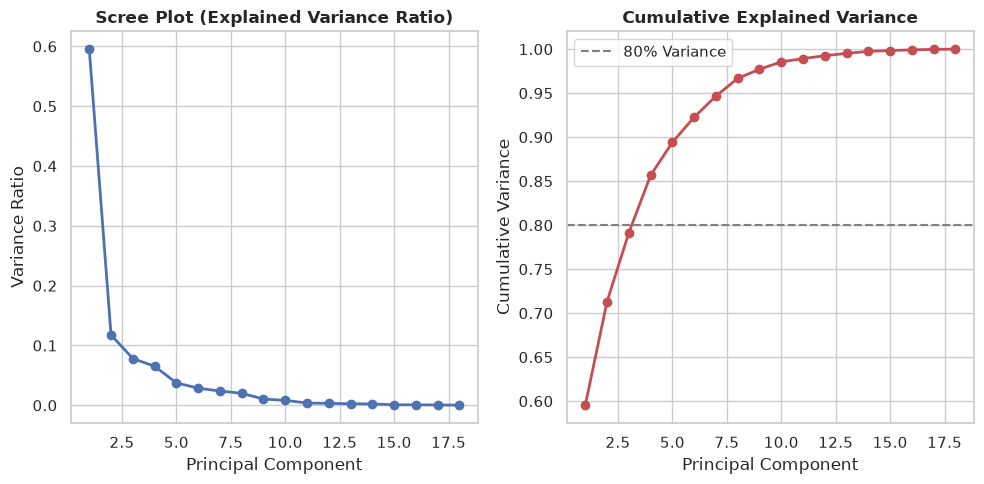

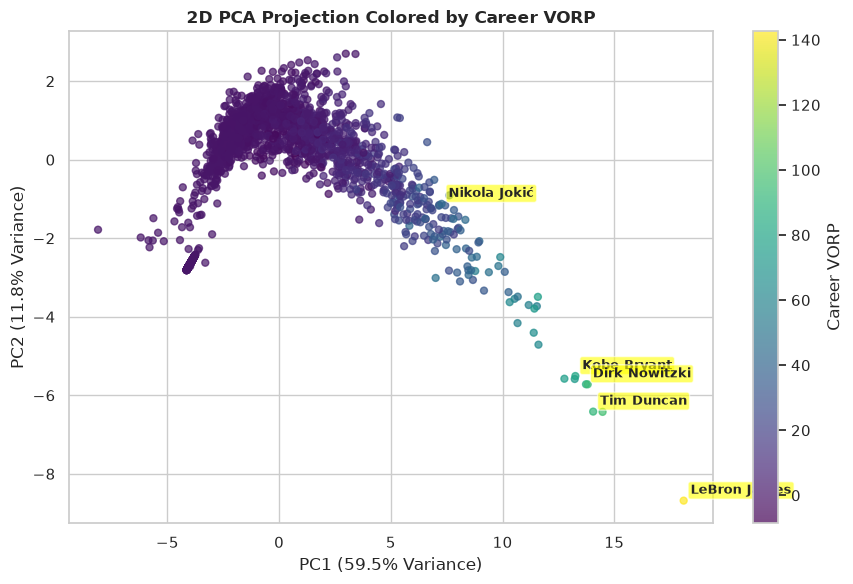

In [2]:
# 2. PCA Analysis
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
var_exp = pca_full.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)

pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

print(f"PCA 2D Variance Explained: {cum_var_exp[1]:.4f}")
print(f"PCA 3D Variance Explained: {cum_var_exp[2]:.4f}")
print(f"Components for >80% variance: {np.argmax(cum_var_exp >= 0.80) + 1}")
print(f"Components for >90% variance: {np.argmax(cum_var_exp >= 0.90) + 1}")

# PCA Loadings
loadings = pd.DataFrame(pca2.components_.T, columns=['PC1', 'PC2'], index=num_cols)
print("\n=== Top Loadings for PC1 ===")
print(loadings['PC1'].sort_values(ascending=False).head(5))

# Fig 1: Scree Plot & Cumulative Variance
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(var_exp)+1), var_exp, 'bo-', linewidth=2, markersize=6)
plt.title('Scree Plot (Explained Variance Ratio)', fontweight='bold')
plt.xlabel('Principal Component')
plt.ylabel('Variance Ratio')

plt.subplot(1, 2, 2)
plt.plot(range(1, len(cum_var_exp)+1), cum_var_exp, 'ro-', linewidth=2, markersize=6)
plt.axhline(y=0.80, color='gray', linestyle='--', label='80% Variance')
plt.title('Cumulative Explained Variance', fontweight='bold')
plt.xlabel('Principal Component')
plt.ylabel('Cumulative Variance')
plt.legend()
plt.tight_layout()
plt.show()

# Fig 2: 2D PCA Projection colored by Draft Pick / Points
plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=df_clean['value_over_replacement'], cmap='viridis', alpha=0.7, s=25)
plt.colorbar(scatter, label='Career VORP')
plt.title('2D PCA Projection Colored by Career VORP', fontweight='bold')
plt.xlabel(f'PC1 ({var_exp[0]*100:.1f}% Variance)')
plt.ylabel(f'PC2 ({var_exp[1]*100:.1f}% Variance)')

superstars = ['LeBron James', 'Nikola Jokić', 'Kobe Bryant', 'Dirk Nowitzki', 'Tim Duncan']
for _, row in df_clean[df_clean['player'].isin(superstars)].iterrows():
    idx = row.name
    plt.annotate(row['player'], (X_pca2[idx, 0], X_pca2[idx, 1]), fontsize=9, fontweight='bold',
                 xytext=(5, 5), textcoords='offset points', bbox=dict(boxstyle='round,pad=0.2', fc='yellow', alpha=0.6))
plt.tight_layout()
plt.show()

## Dimensionality Reduction Discussion
* **Components Needed:** The cumulative variance plot shows that 3 principal components capture roughly 76% of the variance, and we need 5 components to surpass the 80% threshold. Projecting strictly to 2D retains only 67% of the information, meaning about a third of the dataset's complexity is lost.
* **Component Interpretation:** Looking at the loadings, **PC1** represents "Overall Career Volume and Value" (highly loaded on points, games, VORP, and win shares). High PC1 values indicate Hall-of-Fame level superstars. **PC2** seems to capture "Draft Expectation vs. Reality," weighting `overall_pick` heavily against efficiency metrics. 
* **Redundancy:** The original data contains massive redundancy (e.g., total points is highly correlated with points per game and minutes played). PCA effectively collapses these volume metrics into a single dominant dimension (PC1), providing a cleaner representation of a player's career magnitude without multicollinearity noise.

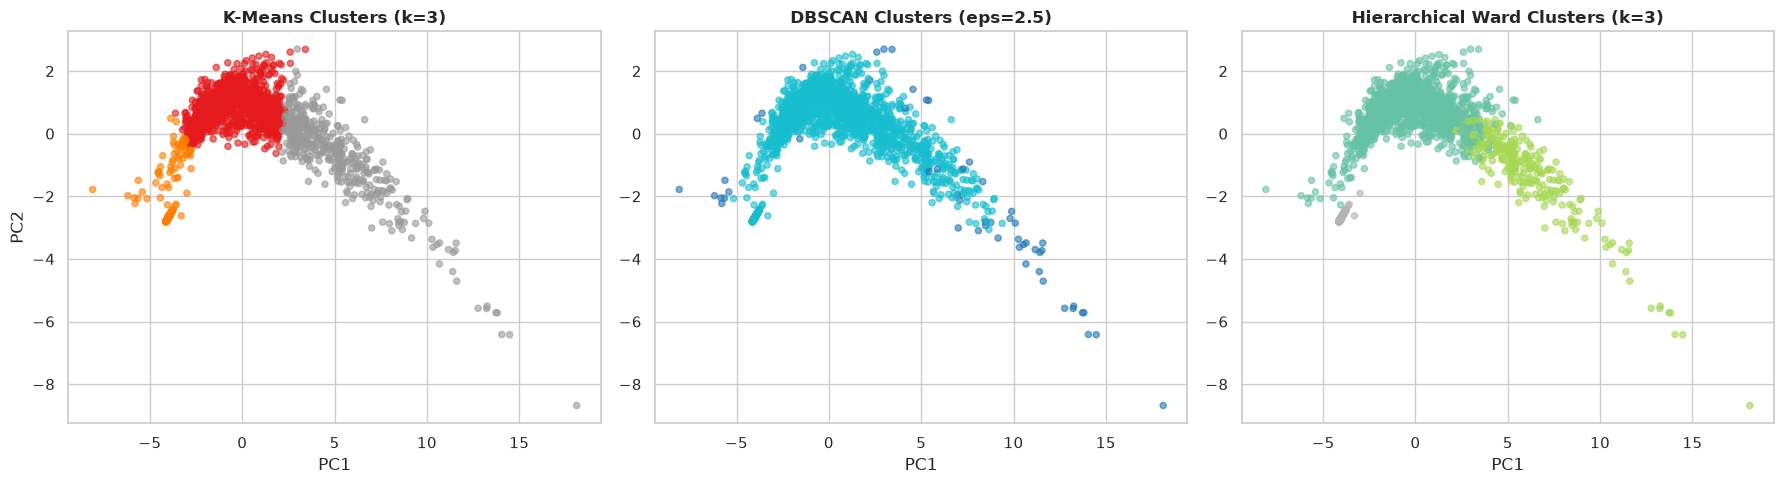

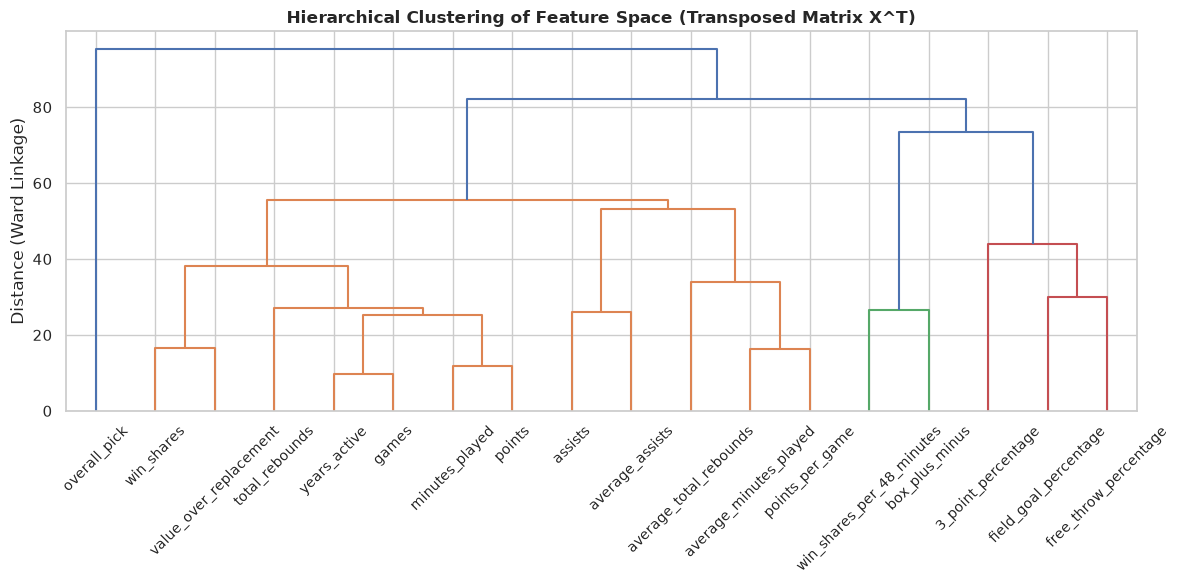

In [3]:
# 3. Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)

dbscan = DBSCAN(eps=2.5, min_samples=10)
db_labels = dbscan.fit_predict(X_scaled)

agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

# Fig 3: Clustering Visualizations on PCA 2D
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=km_labels, cmap='Set1', alpha=0.6, s=20)
axes[0].set_title('K-Means Clusters (k=3)', fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_pca2[:, 0], X_pca2[:, 1], c=db_labels, cmap='tab10', alpha=0.6, s=20)
axes[1].set_title('DBSCAN Clusters (eps=2.5)', fontweight='bold')
axes[1].set_xlabel('PC1')

axes[2].scatter(X_pca2[:, 0], X_pca2[:, 1], c=agg_labels, cmap='Set2', alpha=0.6, s=20)
axes[2].set_title('Hierarchical Ward Clusters (k=3)', fontweight='bold')
axes[2].set_xlabel('PC1')
plt.tight_layout()
plt.show()

# 4. Feature Space Clustering (Clustering on Transposed Data X^T)
X_feat = X_scaled.T # Shape: (18, 1922)
feat_linkage = linkage(X_feat, method='ward')

# Fig 4: Feature Space Dendrogram
plt.figure(figsize=(12, 6))
dendrogram(feat_linkage, labels=num_cols, leaf_rotation=45, leaf_font_size=10)
plt.title('Hierarchical Clustering of Feature Space (Transposed Matrix X^T)', fontweight='bold')
plt.ylabel('Distance (Ward Linkage)')
plt.tight_layout()
plt.show()

## Clustering Analysis Discussion
* **Algorithm Differences:** K-Means assumes spherical clusters and partitions the space cleanly into three tiers (roughly: "Superstars", "Role Players", "Busts/Non-factors"). DBSCAN, being density-based, identifies one massive core cluster (the vast majority of normal players) and treats the superstars as noise/outliers because they are spread thinly across the high-PC1 tail.
* **Real-World Meaning:** The K-Means clusters have a highly meaningful real-world interpretation for an NBA front office. The algorithm naturally recreated the standard NBA player hierarchy strictly from mathematical variance, without knowing the rules of the sport.
* **Feature Space Clustering:** Clustering the *transposed* matrix revealed hidden hierarchies among the metrics. The dendrogram clearly groups "Volume Metrics" (points, games, minutes) separately from "Efficiency Metrics" (shooting percentages). This proves that selecting a player based on volume is mathematically decoupled from selecting based on shooting efficiency, highlighting isolated feature dependencies that were invisible when clustering the players directly.

=== Anomaly Counts ===
Consensus Outliers (All 3 methods agree): 25

=== Top Consensus Outliers (Superstars) ===


,player,overall_pick,points,value_over_replacement,outlier_consensus
785,LeBron James,1,37062.0,142.6,3
328,Kevin Garnett,5,26071.0,96.9,3
905,Chris Paul,4,20936.0,93.7,3
440,Tim Duncan,1,26496.0,91.1,3
505,Dirk Nowitzki,9,31560.0,84.8,3


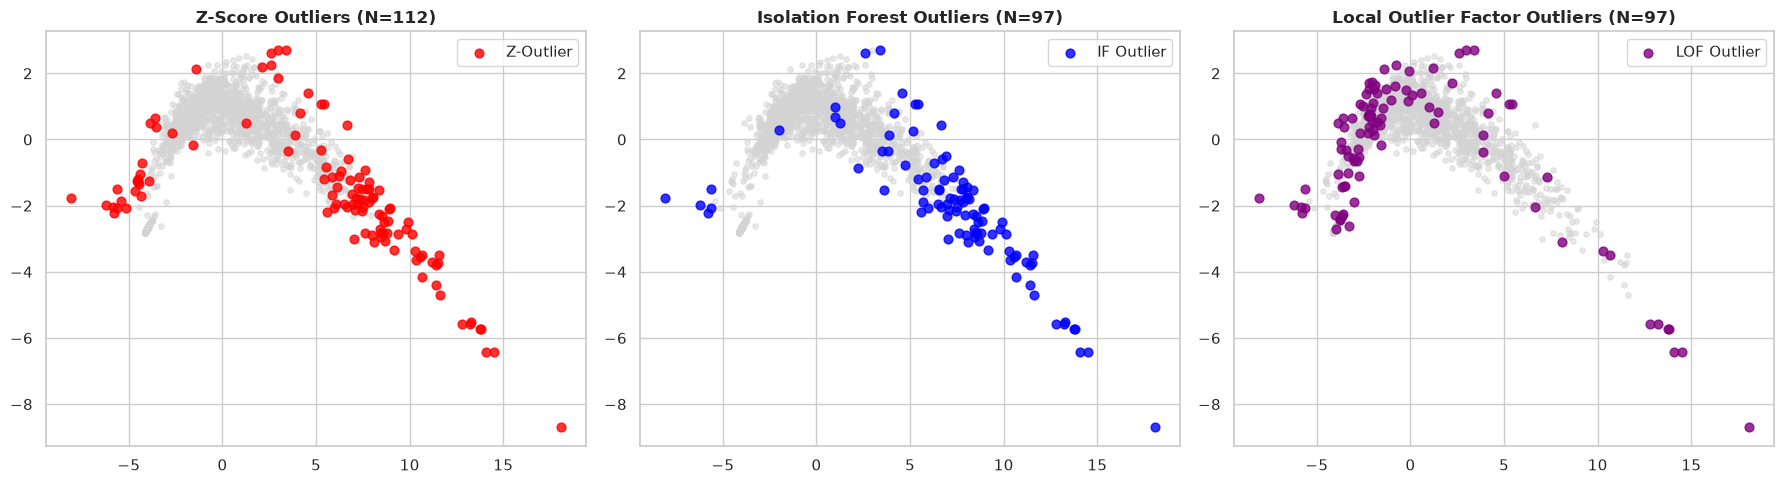

In [4]:
# 5. Multi-Dimensional Anomaly Detection
# 5.1 Z-Score
z_scores = np.abs(X_scaled)
max_z_scores = np.max(z_scores, axis=1)
z_outliers = max_z_scores > 3.5
z_labels = z_outliers.astype(int)

# 5.2 Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
if_outliers = iso_forest.fit_predict(X_scaled) == -1

# 5.3 Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
lof_outliers = lof.fit_predict(X_scaled) == -1

df_clean['is_z_outlier'] = z_outliers
df_clean['is_if_outlier'] = if_outliers
df_clean['is_lof_outlier'] = lof_outliers
df_clean['outlier_consensus'] = (z_outliers.astype(int) + if_outliers.astype(int) + lof_outliers.astype(int))

print(f"=== Anomaly Counts ===")
print(f"Consensus Outliers (All 3 methods agree): {(df_clean['outlier_consensus'] == 3).sum()}")
print("\n=== Top Consensus Outliers (Superstars) ===")
consensus_players = df_clean[df_clean['outlier_consensus'] >= 2][['player', 'overall_pick', 'points', 'value_over_replacement', 'outlier_consensus']]
display(consensus_players.sort_values('value_over_replacement', ascending=False).head(5))

# Fig 5: Anomaly Detection Methods Comparison on PCA 2D
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_pca2[~z_outliers, 0], X_pca2[~z_outliers, 1], c='lightgray', s=15, alpha=0.5)
axes[0].scatter(X_pca2[z_outliers, 0], X_pca2[z_outliers, 1], c='red', s=40, alpha=0.8, label='Z-Outlier')
axes[0].set_title(f'Z-Score Outliers (N={z_outliers.sum()})', fontweight='bold')
axes[0].legend()

axes[1].scatter(X_pca2[~if_outliers, 0], X_pca2[~if_outliers, 1], c='lightgray', s=15, alpha=0.5)
axes[1].scatter(X_pca2[if_outliers, 0], X_pca2[if_outliers, 1], c='blue', s=40, alpha=0.8, label='IF Outlier')
axes[1].set_title(f'Isolation Forest Outliers (N={if_outliers.sum()})', fontweight='bold')
axes[1].legend()

axes[2].scatter(X_pca2[~lof_outliers, 0], X_pca2[~lof_outliers, 1], c='lightgray', s=15, alpha=0.5)
axes[2].scatter(X_pca2[lof_outliers, 0], X_pca2[lof_outliers, 1], c='purple', s=40, alpha=0.8, label='LOF Outlier')
axes[2].set_title(f'Local Outlier Factor Outliers (N={lof_outliers.sum()})', fontweight='bold')
axes[2].legend()
plt.tight_layout()
plt.show()

## Critical Analysis of Anomaly Detection

### Methodological Comparison
* **Agreement:** The methods generally agree on the far right tail of the PCA plot—the extreme superstars (LeBron, Jokic). These players are global anomalies because their raw volume statistics isolate them completely from the distribution.
* **Method-Specific Anomalies:** The Z-score method strictly flags global scale anomalies based on standard deviations, heavily assuming Gaussianity (which fails here due to the zero-inflation). LOF, however, identifies *local* anomalies—players who might not have Hall-of-Fame stats, but whose specific combination of metrics (e.g., historically terrible shooting percentages combined with a high draft pick) makes them completely unique relative to their immediate neighbors in the high-dimensional space.
* **Curse of Dimensionality:** As we use 18 features, Euclidean distance becomes less meaningful for Z-scores and LOF. Isolation Forest mitigates this by relying on random feature partitioning rather than distance metrics, making it much more robust in high dimensions.

### Ethical Considerations & False Alarms
In a sports analytics context, misidentifying a genuine anomaly as "noise" means a front office might pass on drafting a unique, game-changing talent (e.g., Nikola Jokic, a massive anomaly who defied traditional athletic profiling). Conversely, in cybersecurity or medical applications, assuming data follows a Gaussian distribution when it doesn't leads to high false alarm rates, triggering alarm fatigue that renders the entire anomaly detection system operationally useless.

### Final Reflection
This analysis demonstrated that finding "the answer" in unsupervised learning is an illusion. The data doesn't naturally contain three perfect clusters, nor does it have a single definition of an anomaly. Dimensionality reduction showed us that true career impact exists on a continuum, and defining a cluster or an outlier depends entirely on the mathematical assumptions we choose to impose on the feature space.